# Étape 0 – Données

**Objectif :** vérifier le jeu d'entraînement produit par Julia, mesurer le coût de sa génération, **comparer avec
une génération en Python** (mêmes surfaces ? combien de temps ?), et préparer la surface réelle SPX.

**Avant ce notebook :** les données sont générées et le temps de Fourier est mesuré en Julia (`julia/generate_data.jl`
et `julia/benchmark.jl`, voir le README).
Le pricer Python (`heston_nn.pricing.heston_cos`) est une copie fidèle du pricer Julia (`julia/src/HestonFourier.jl`) :
mêmes formules, mêmes réglages. Seule différence : l'inversion de Black-76 se fait par dichotomie au lieu de Brent.

**Configuration :** imports, règles communes (`configs/base.yaml`), grille, et `N_JOBS`, le nombre de processus
pour la génération Python (l'équivalent des threads de Julia).

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from heston_nn.config import load_config, repo_path
from heston_nn.data.dataset import check_dataset, load_dataset
from heston_nn.data.grid import get_grid, vector_to_surface
from heston_nn.plots import plot_error_heatmap, plot_surface
from heston_nn.pricing import heston_cos

cfg = load_config("configs/base.yaml")
maturities, moneyness = get_grid(cfg)

N_JOBS = os.cpu_count()     # processus pour la génération Python
FIGURES = repo_path("results", "figures")
print("Grille :", len(maturities), "maturités x", len(moneyness), "strikes ;", N_JOBS, "processus disponibles")

Grille : 8 maturités x 11 strikes ; 20 processus disponibles


## 1. Charger et vérifier le jeu d'entraînement
Chargement de `data/surfaces.npz`, vérification du contrat (`check_dataset` : X (N, 5), Y (N, 88), valeurs
plausibles), puis la part de NaN par point de la grille : ils sont attendus à T = 0,1 sur les strikes extrêmes
(options trop loin de la monnaie pour avoir un prix fiable).

X : (50000, 5)  Y : (50000, 88)
{'n_surfaces': 50000, 'n_surfaces_with_nan': 28078, 'n_nan_points': 83827, 'share_nan_points': 0.01905159090909091}
Surfaces avec au moins un NaN : 56.2%
Points NaN : 1.91% (dont 0.34% hors T = 0,1)


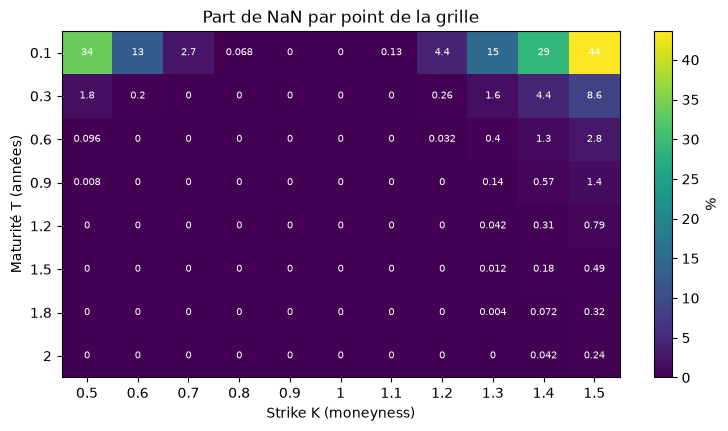

In [2]:
X, Y = load_dataset(repo_path("data", "surfaces.npz"))
print("X :", X.shape, " Y :", Y.shape)
print(check_dataset(X, Y, cfg))

nan_share = 100 * np.isnan(Y).mean(axis=0).reshape(len(maturities), len(moneyness))
print(f"Surfaces avec au moins un NaN : {np.isnan(Y).any(axis=1).mean():.1%}")
print(f"Points NaN : {np.isnan(Y).mean():.2%} (dont {np.isnan(Y[:, len(moneyness):]).mean():.2%} hors T = 0,1)")
plot_error_heatmap(nan_share, maturities, moneyness, title="Part de NaN par point de la grille", unit="%",
                   save_path=FIGURES / "etape0_nan.png")
plt.show()

**Répartition des volatilités.** Les plages de `base.yaml` tirent v0 et theta uniformément en vol (et non en
variance) pour qu'une bonne part des surfaces soit dans la zone habituelle du SPX (10 à 25 %). Vérification sur la
vol ATM (K = 1) à 1 mois et à 1,2 an.

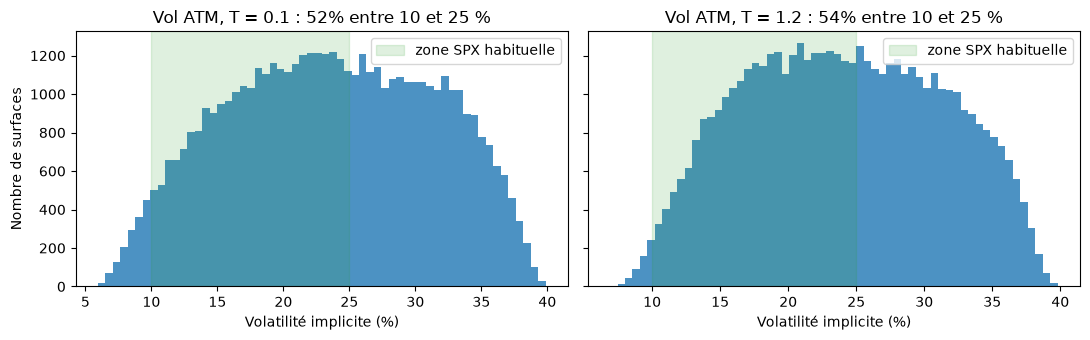

In [3]:
atm = moneyness.tolist().index(1.0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for axis, i in zip(axes, [0, 4]):
    vols = 100 * Y[:, i * len(moneyness) + atm]
    vols = vols[~np.isnan(vols)]
    axis.hist(vols, bins=60, color="tab:blue", alpha=0.8)
    axis.axvspan(10, 25, color="tab:green", alpha=0.15, label="zone SPX habituelle")
    axis.set_title(f"Vol ATM, T = {maturities[i]:g} : {np.mean((vols >= 10) & (vols <= 25)):.0%} entre 10 et 25 %")
    axis.set_xlabel("Volatilité implicite (%)")
    axis.legend()
axes[0].set_ylabel("Nombre de surfaces")
plt.tight_layout()
plt.savefig(FIGURES / "etape0_vols_atm.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Coût initial (Julia)
Temps écrits par Julia : génération complète (`generation_time.json`, en parallèle) et une surface sur un seul
thread (`fourier_time.json` : médiane sur les 200 premières surfaces de `data/surfaces.npz`, 5 mesures par
surface). C'est ce dernier que le réseau devra battre.

In [4]:
with open(repo_path("results", "etape0", "generation_time.json")) as f:
    julia_generation = json.load(f)
with open(repo_path("results", "etape0", "fourier_time.json")) as f:
    julia_fourier = json.load(f)

print(f"Génération Julia : {julia_generation['n_surfaces']} surfaces en {julia_generation['seconds']:.1f} s "
      f"sur {julia_generation['n_threads']} threads ({julia_generation['machine']})")
print(f"Fourier Julia, une surface, 1 thread : {1e3 * julia_fourier['median_s']:.2f} ms (médiane)")

Génération Julia : 50000 surfaces en 23.9 s sur 20 threads (znver5)
Fourier Julia, une surface, 1 thread : 2.29 ms (médiane)


## 3. Visualiser quelques surfaces
Quatre surfaces tirées au hasard : un smile par maturité. Attendu : un skew négatif (vol plus élevée pour les petits
strikes, car ρ < 0), qui s'aplatit quand la maturité augmente.

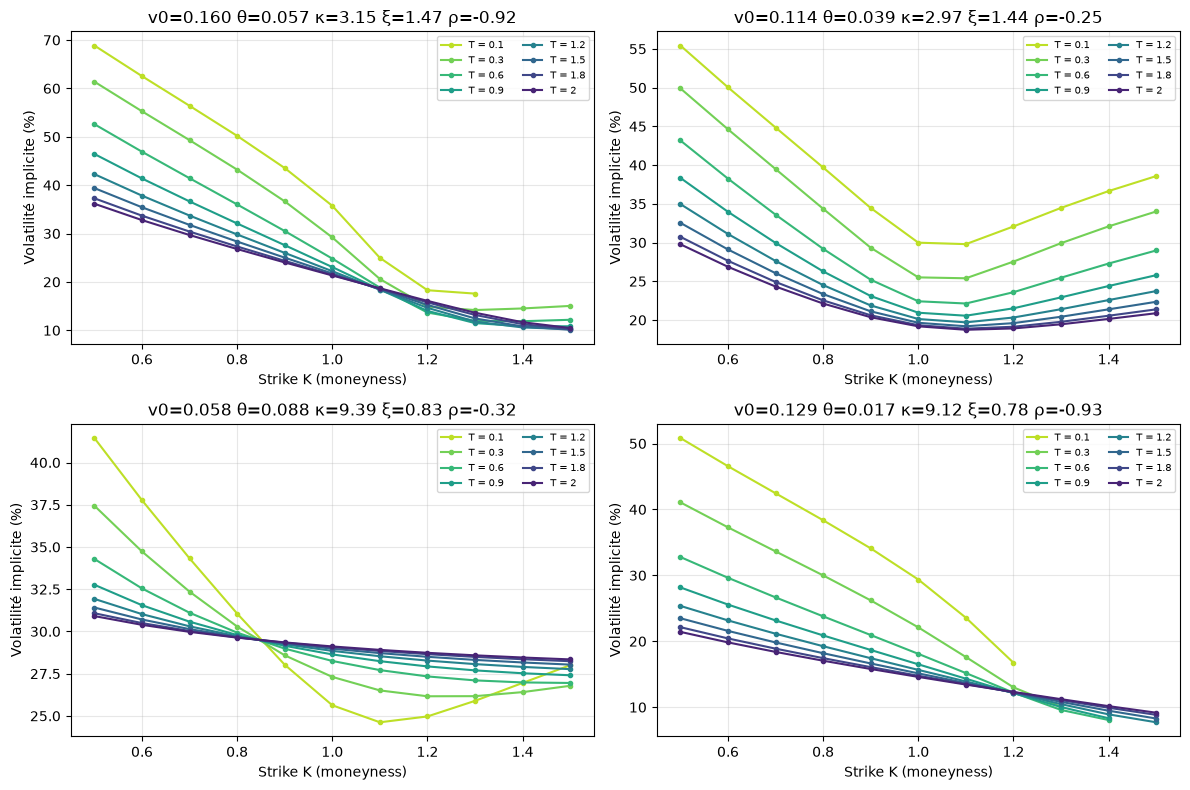

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, i in zip(axes.ravel(), rng.choice(len(X), 4, replace=False)):
    v0, theta, kappa, xi, rho = X[i]
    plot_surface(vector_to_surface(Y[i]), maturities, moneyness, axis=axis,
                 title=f"v0={v0:.3f} θ={theta:.3f} κ={kappa:.2f} ξ={xi:.2f} ρ={rho:.2f}")
plt.tight_layout()
plt.savefig(FIGURES / "etape0_surfaces.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Génération en Python : mêmes surfaces ? Combien de temps ?

On recalcule les surfaces avec le pricer Python **à partir des mêmes paramètres X que Julia** (on ne peut pas
reproduire le tirage : les générateurs aléatoires de Julia et de numpy sont différents), puis on compare.

### 4.1 Mêmes surfaces ?
Les 50 000 surfaces sont recalculées en Python, réparties sur `N_JOBS` processus. Le temps mesuré est aussi celui
de la génération complète en Python.

In [6]:
start = time.perf_counter()
Y_python = heston_cos.generate_surfaces(X, maturities, moneyness, n_jobs=N_JOBS)
python_seconds = time.perf_counter() - start

same_nan = np.isnan(Y_python) == np.isnan(Y)
both = ~np.isnan(Y_python) & ~np.isnan(Y)
gap_bp = 1e4 * np.abs(Y_python - Y)          # écart en points de base (1 pb = 0,01 % de vol)
print(f"{len(X)} surfaces en {python_seconds:.1f} s sur {N_JOBS} processus")
print(f"NaN au même endroit : {same_nan.mean():.4%} des points ({(~same_nan).sum()} différences)")
print(f"Écart Python / Julia : moyen {gap_bp[both].mean():.1e} pb, 99,99 % des points sous "
      f"{np.quantile(gap_bp[both], 0.9999):.1e} pb, max {gap_bp[both].max():.1e} pb")

50000 surfaces en 89.1 s sur 20 processus
NaN au même endroit : 100.0000% des points (0 différences)
Écart Python / Julia : moyen 1.2e-06 pb, 99,99 % des points sous 1.6e-03 pb, max 6.6e-02 pb


Écart maximal par point de la grille : s'il y a un écart, on voit où il se trouve.

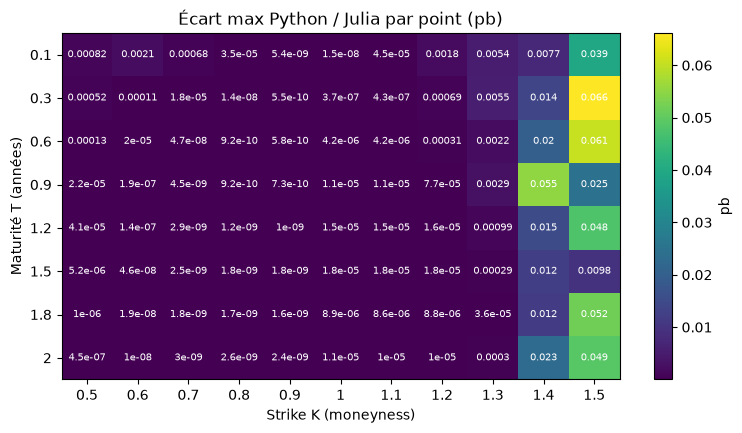

In [7]:
max_gap = np.where(both, gap_bp, 0).max(axis=0).reshape(len(maturities), len(moneyness))
plot_error_heatmap(max_gap, maturities, moneyness, title="Écart max Python / Julia par point (pb)",
                   save_path=FIGURES / "etape0_python_vs_julia.png")
plt.show()

### 4.2 Combien de temps pour une surface ?
Exactement la même mesure que `julia/benchmark.jl`, pour que les deux temps soient comparables : les mêmes
200 jeux de paramètres (les 200 premières surfaces de `data/surfaces.npz`), un seul cœur, et pour chaque jeu un
appel à blanc puis 5 mesures dont on garde la médiane. Le temps retenu est la médiane sur les 200 jeux.

In [8]:
N_SETS, N_REPEATS = 200, 5          # mêmes réglages que julia/benchmark.jl
timings = []
for params in X[:N_SETS]:
    heston_cos.price_surface(params, maturities, moneyness)          # appel à blanc, comme Julia
    runs = []
    for _ in range(N_REPEATS):
        start = time.perf_counter()
        heston_cos.price_surface(params, maturities, moneyness)
        runs.append(time.perf_counter() - start)
    timings.append(np.median(runs))
python_fourier = float(np.median(timings))
print(f"Fourier Python, une surface, 1 cœur : {1e3 * python_fourier:.2f} ms (médiane sur {N_SETS} jeux, "
      f"{N_REPEATS} mesures chacun)")

Fourier Python, une surface, 1 cœur : 11.04 ms (médiane sur 200 jeux, 5 mesures chacun)


### 4.3 Bilan Julia / Python

In [9]:
summary = pd.DataFrame({
    "Julia": [julia_generation["seconds"], julia_generation["n_threads"], 1e3 * julia_fourier["median_s"]],
    "Python": [python_seconds, N_JOBS, 1e3 * python_fourier],
}, index=["Génération de 50 000 surfaces (s)", "Threads / processus", "Une surface, 1 cœur (ms)"])
summary["Python / Julia"] = summary["Python"] / summary["Julia"]
summary.loc["Threads / processus", "Python / Julia"] = np.nan     # pas un temps : pas de rapport
display(summary.round(2))

result = {"python_generation_s": python_seconds, "n_jobs": N_JOBS,
          "python_surface_median_s": python_fourier,
          "nan_differences": int((~same_nan).sum()), "max_gap_bp": float(gap_bp[both].max()),
          "mean_gap_bp": float(gap_bp[both].mean())}
with open(repo_path("results", "etape0", "python_vs_julia.json"), "w") as f:
    json.dump(result, f, indent=4)

,Julia,Python,Python / Julia
Génération de 50 000 surfaces (s),23.92,89.06,3.72
Threads / processus,20.00,20.00,NaN
"Une surface, 1 cœur (ms)",2.29,11.04,4.82


## 5. Surface réelle SPX

Le pipeline est dans `data/market.py` : cotations Yahoo Finance → nettoyage → forward et actualisation par la parité
call-put (un taux par jour) → vols implicites (Black-76) → smile SVI par échéance → grille 8 × 11, avec un
**masque** des points vraiment cotés.

**Plusieurs jours.** Yahoo Finance ne donne que les cotations du moment : chaque jour est téléchargé pendant les
heures d'ouverture américaines (15 h 30 – 22 h, heure de Paris) et le fichier brut est gardé dans `data/spx/raw/`.
`data/spx_surface.npz` est reconstruit avec tous les jours ; c'est ce fichier que lit le notebook 04. La cellule 5.1
ajoute le jour courant s'il n'est pas encore collecté (rien le week-end ou si le jour est déjà là).

**On calibre uniquement sur les points vraiment cotés** : dans `spx_surface.npz`, les points extrapolés par SVI
valent NaN (ce sont des artefacts du lissage, pas des prix).

### 5.1 Collecter la surface du jour

In [10]:
from functools import partial

from heston_nn.calibration.calibrate import calibrate
from heston_nn.data import market
from heston_nn.data.grid import calibration_zone

result = market.collect()      # télécharge, construit la surface, enregistre ; None si déjà fait aujourd'hui ou week-end
if result is not None:
    surface_today, mask_today, smiles_today, info_today = result
    print(info_today)
    display(smiles_today[["expiry", "T", "F", "D", "rmse"]].round(4))   # une ligne par échéance retenue
market.summary(market.DEFAULT_OUTDIR)

It's the weekend, Yahoo would return stale quotes. Try on a weekday.
trade_date        spot  n_expiries_used  pct_quoted  n_calendar_violations
2026-11-03 7568.919922               44   82.954545                      7
2026-11-04 7688.620117               43   81.818182                      7
2026-11-05 7422.459961               42   82.954545                      7
2026-11-20 7139.870117               42   87.500000                      4

4 day(s) collected.


### 5.2 Les jours collectés
Pour chaque jour : points cotés, vol ATM à 1 mois et à 1,2 an, et violations d'arbitrage calendaire (la variance
totale doit croître avec la maturité). On vérifie aussi que les vols SPX tombent **dans le domaine des données
d'entraînement** : sinon le réseau devrait extrapoler.

In [11]:
with np.load(market.CALIBRATION_FILE) as f:     # lu puis refermé : sous Windows, un fichier ouvert ne peut
    spx = dict(f)                                 # plus être modifié (collecte d'un nouveau jour, git pull)
dates, surfaces, masks, full = spx["dates"], spx["surfaces"], spx["masks"], spx["surfaces_full"]

atm = moneyness.tolist().index(1.0)
train_atm_1m = Y[:, atm][~np.isnan(Y[:, atm])]                              # vol ATM 1 mois des données
train_atm_12 = Y[:, 4 * len(moneyness) + atm]
train_atm_12 = train_atm_12[~np.isnan(train_atm_12)]                     # vol ATM 1,2 an des données
days = pd.DataFrame({
    "spot": spx["spots"],
    "points cotés": masks.sum(axis=(1, 2)),
    "vol ATM 1 mois (%)": 100 * full[:, 0, atm],
    "vol ATM 1,2 an (%)": 100 * full[:, 4, atm],
    "violations calendaires": [int((np.diff(f**2 * maturities[:, None], axis=0) < -1e-6).sum()) for f in full],
}, index=dates)
display(days.round(2))

for name, values, train in [("1 mois", full[:, 0, atm], train_atm_1m), ("1,2 an", full[:, 4, atm], train_atm_12)]:
    share = np.array([np.mean(train <= v) for v in values])                # rang dans les données d'entraînement
    print(f"Vol ATM {name} : percentile dans les données d'entraînement = {np.round(100 * share).astype(int)} "
          f"(0 ou 100 = hors du domaine)")

,spot,points cotés,vol ATM 1 mois (%),"vol ATM 1,2 an (%)",violations calendaires
2026-11-03,7568.92,73,16.03,17.19,7
2026-11-04,7688.62,72,13.44,16.58,7
2026-11-05,7422.46,73,19.57,17.92,7
2026-11-20,7139.87,77,22.53,19.74,4


Vol ATM 1 mois : percentile dans les données d'entraînement = [20 11 33 45] (0 ou 100 = hors du domaine)
Vol ATM 1,2 an : percentile dans les données d'entraînement = [21 18 24 32] (0 ou 100 = hors du domaine)


Surface du dernier jour (points cotés seulement) et masque des points cotés.

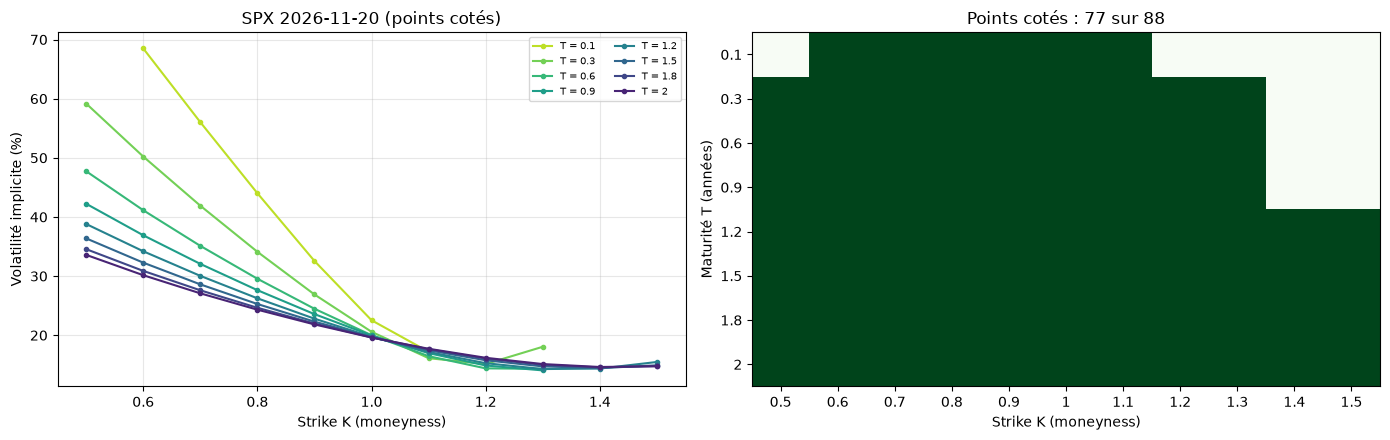

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_surface(surfaces[-1], maturities, moneyness, axis=axes[0], title=f"SPX {dates[-1]} (points cotés)")
image = axes[1].imshow(masks[-1], cmap="Greens", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(moneyness)), [f"{k:g}" for k in moneyness])
axes[1].set_yticks(range(len(maturities)), [f"{t:g}" for t in maturities])
axes[1].set_xlabel("Strike K (moneyness)")
axes[1].set_ylabel("Maturité T (années)")
axes[1].set_title(f"Points cotés : {masks[-1].sum()} sur {masks[-1].size}")
plt.tight_layout()
plt.savefig(FIGURES / "etape0_spx.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Calibration d'essai (Fourier Python)
Avant l'étape 4 : calibrer chaque jour avec le pricer Fourier Python (`heston_cos`, identique au Julia) et le même
optimiseur que le notebook 04 (Levenberg–Marquardt, 5 points de départ), **sur la zone de calibration de `base.yaml`**
(`spx_calibration` : strikes de 0,7 à 1,3, maturités ≥ 0,3). Heston ne sait pas reproduire le skew très raide à 1 mois
ni les ailes extrêmes : on calibre sur la zone liquide, proche de la monnaie, et on le dit dans le rapport.

Ce qu'on vérifie :
- **les paramètres collent-ils à une borne** de `param_ranges` ?
- **le ratio de Feller 2κθ/ξ² est-il ≥ 0,1** (`min_feller_ratio`) ? Sinon le résultat sort du domaine appris par le réseau ;
- l'erreur d'ajustement sur la zone, et, pour information, sur tous les points cotés.

In [13]:
fourier_python = partial(heston_cos.price_surface, maturities=maturities, moneyness=moneyness)
names = list(heston_cos.PARAM_NAMES)
bounds = np.array([cfg["param_ranges"][n] for n in names], dtype=float)
zone = calibration_zone(cfg)                                  # (8, 11) : True dans la zone de calibration

rows, calibrated = [], []
for date, surface in zip(dates, surfaces):
    target = np.where(zone, surface, np.nan)                  # seulement les points cotés ET dans la zone
    params, infos = calibrate(target, fourier_python, cfg["param_ranges"], n_starts=5, seed=0)
    fit = fourier_python(params)
    distance = np.minimum(params - bounds[:, 0], bounds[:, 1] - params) / (bounds[:, 1] - bounds[:, 0])
    rows.append({"date": date, **dict(zip(names, params)),
                 "Feller 2κθ/ξ²": 2 * params[2] * params[1] / params[3] ** 2,
                 "à une borne": ", ".join(n for n, d in zip(names, distance) if d < 0.01) or "-",
                 "points utilisés": infos["n_points"],
                 "erreur moyenne zone (pb)": infos["fit_error_bp"], "erreur max zone (pb)": infos["max_error_bp"],
                 "erreur moyenne tous cotés (pb)": 1e4 * np.nanmean(np.abs(fit - surface)),
                 "temps (s)": infos["time_s"]})
    calibrated.append(fit)
calibration = pd.DataFrame(rows).set_index("date")
display(calibration.round(4))
calibration.to_csv(repo_path("results", "etape0", "spx_calibration_fourier.csv"))

,v0,theta,kappa,xi,rho,Feller 2κθ/ξ²,à une borne,points utilisés,erreur moyenne zone (pb),erreur max zone (pb),erreur moyenne tous cotés (pb),temps (s)
date,,,,,,,,,,,,
2026-11-03,0.0362,0.0493,3.8872,1.5,-0.7196,0.1703,xi,46,29.1934,145.8843,97.6823,7.4495
2026-11-04,0.0231,0.0485,3.9930,1.5,-0.7131,0.1722,xi,47,29.5002,125.0148,120.1329,8.0102
2026-11-05,0.0531,0.0505,3.8162,1.5,-0.7519,0.1711,xi,46,29.0984,165.0558,140.6356,10.2999
2026-11-20,0.0764,0.0552,3.8873,1.5,-0.7614,0.1908,xi,49,29.8411,123.3395,94.0483,7.9451


Ajustement du dernier jour, maturité par maturité : points du marché dans la zone de calibration (noirs) et hors zone (gris), et Heston calibré (trait).

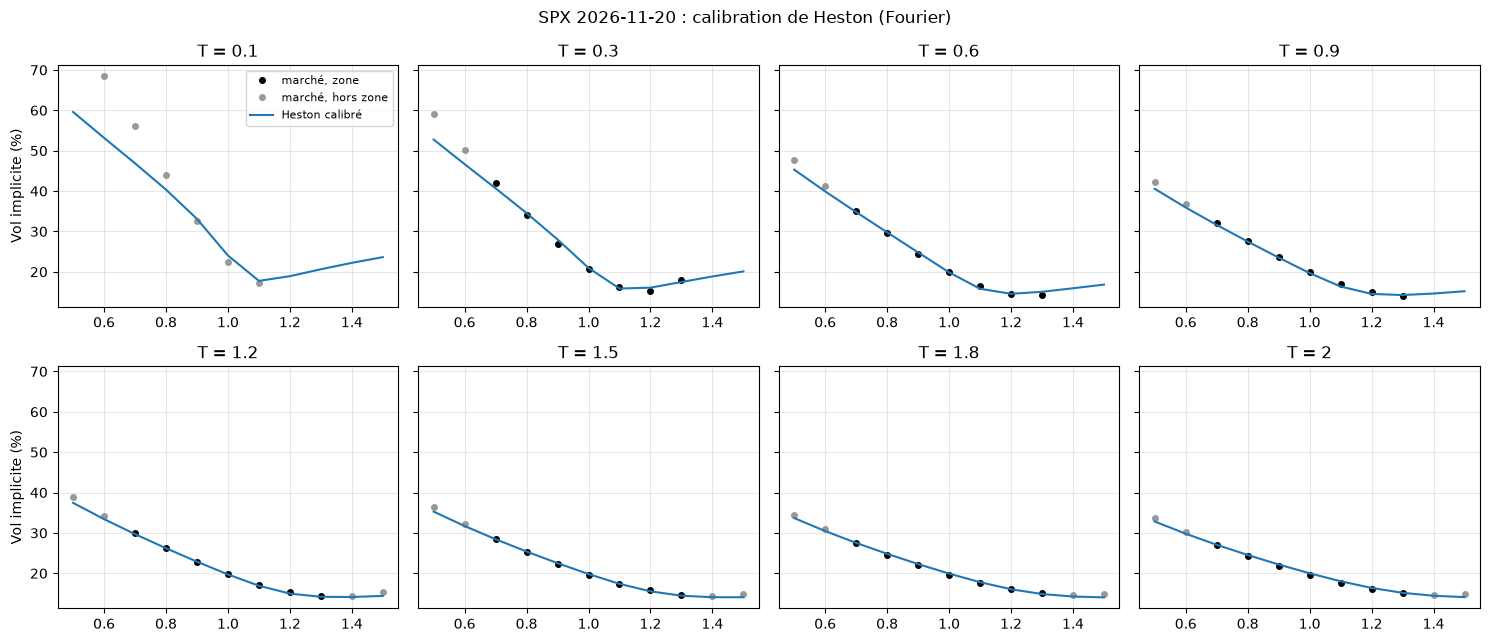

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for i, axis in enumerate(axes.ravel()):
    in_zone = zone[i]
    axis.plot(moneyness[in_zone], 100 * surfaces[-1][i][in_zone], "ko", markersize=4, label="marché, zone")
    axis.plot(moneyness[~in_zone], 100 * surfaces[-1][i][~in_zone], "o", color="0.6", markersize=4,
              label="marché, hors zone")
    axis.plot(moneyness, 100 * calibrated[-1][i], "-", color="tab:blue", label="Heston calibré")
    axis.set_title(f"T = {maturities[i]:g}")
    axis.grid(True, alpha=0.3)
axes[0, 0].set_ylabel("Vol implicite (%)")
axes[1, 0].set_ylabel("Vol implicite (%)")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"SPX {dates[-1]} : calibration de Heston (Fourier)")
plt.tight_layout()
plt.savefig(FIGURES / "etape0_spx_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

- **Le jeu d'entraînement** : 50 000 surfaces de 88 points. 56 % des surfaces ont au moins un NaN, mais cela ne
  représente que 1,9 % des points, presque tous à T = 0,1 sur les strikes extrêmes (0,34 % au-delà) : des options
  trop loin de la monnaie pour avoir un prix fiable, et de toute façon non cotées. On garde ces surfaces : la perte
  du réseau ignore les NaN. Grâce au tirage en vol, environ la moitié des surfaces (52 % à 1 mois, 54 % à 1,2 an)
  ont une vol ATM dans la zone habituelle du SPX (10 à 25 %).
- **Python et Julia donnent les mêmes surfaces** : NaN exactement aux mêmes points, écart maximal 0,07 pb (moyen
  1e-6 pb), très en dessous de la précision utile. Le petit écart vient de l'inversion de Black-76 (dichotomie en
  Python, Brent en Julia).
- **Julia est plus rapide** : environ 5 fois sur une surface (2,29 ms contre 11,0 ms) et 3,7 fois sur la génération
  complète (24 s contre 89 s sur 20 threads), machine au repos. C'est pourquoi les données sont générées en Julia.
- **Temps de référence pour la suite** : Fourier en Julia, une surface, un thread, **2,29 ms** (médiane). C'est le
  temps que le réseau devra battre.
- **SPX** : 4 jours collectés (3, 4, 5 et 20 novembre 2026), 72 à 77 points cotés sur 88. Les vols ATM tombent
  dans le domaine d'entraînement (percentiles 11 à 45) : le réseau n'aura pas à extrapoler.
- **Calibration d'essai (Fourier)** : sur la zone de calibration, l'erreur moyenne est d'environ 29 pb chaque jour
  (max 123 à 165 pb). Les paramètres sont stables d'un jour à l'autre (κ ≈ 3,9, θ ≈ 0,05, ρ entre −0,71 et
  −0,76) ; v0 suit la vol courte (0,023 le 4 novembre, 0,076 le 20). ξ colle à sa borne 1,5 tous les jours, et le
  ratio de Feller vaut 0,17 à 0,19, au-dessus du minimum 0,1 : les paramètres calibrés restent dans le domaine appris
  par le réseau. Sur tous les points cotés, l'erreur monte à 94 à 141 pb : Heston ne reproduit pas le skew très
  raide à 1 mois ni les ailes extrêmes, d'où la zone de calibration.